<a href="https://colab.research.google.com/github/skywalker0803r/Vedanta/blob/main/alex%E8%9B%9B%E7%B6%B2%E7%AD%96%E7%95%A5%E5%9B%9E%E6%B8%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

正在從 Gate.io 擷取過去 365 天的 BTC/USDT 日 K 線數據...
成功擷取 365 筆 K 線數據 (區間: 2025-08-29 至 2026-08-28)

 📊 Gate.io BTC 幾何網格回測績效報告 (1年)
起始資金    : 10,000.00 USDT
最終資產淨值: 8,676.30 USDT
淨獲利      : -1,323.70 USDT
網格策略 ROI: -13.24%
買入持有 ROI: -26.33% (基準對比)
總成交筆數  : 1080 次


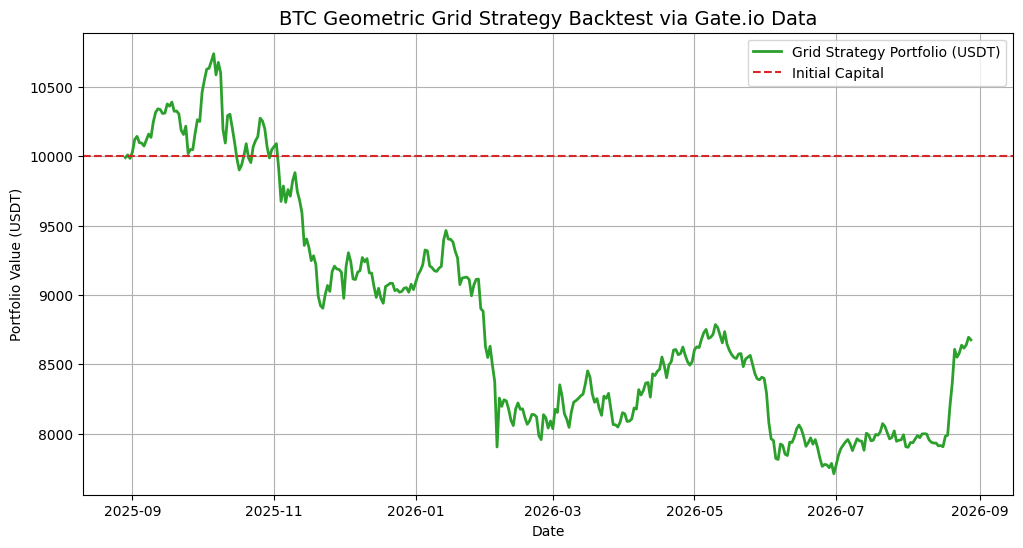

In [3]:
# 1. 安裝必要的第三方套件
!pip install ccxt pandas numpy matplotlib

import ccxt
import pandas as pd
import numpy as np
import math
from datetime import datetime, timedelta, timezone
import matplotlib.pyplot as plt

# ==========================================
# 2. 核心幾何網格公式 (Math Core)
# ==========================================
def seq_order(i: int, j: int, price_r: float, vol_r: float, r: float):
    price = price_r * math.pow(1 + r, i * j)
    sng_vol_step = (1 + 0.5 * r) / (1 + r)
    volume = vol_r * math.pow(sng_vol_step, i * j) * (1 - math.pow(sng_vol_step, -j)) * (-j)
    return abs(price), abs(volume)

# ==========================================
# 3. 抓取 Gate.io 過去一年歷史 K 線 (OHLCV)
# ==========================================
def fetch_btc_gateio_data():
    print("正在從 Gate.io 擷取過去 365 天的 BTC/USDT 日 K 線數據...")

    # 修正點：使用 ccxt.gate()
    exchange = ccxt.gate({
        'enableRateLimit': True,
    })

    # 計算 365 天前的時間戳 (UTC)
    now = datetime.now(timezone.utc)
    start_time = now - timedelta(days=365)
    since = int(start_time.timestamp() * 1000)

    ohlcv = []
    limit = 1000
    while since < int(now.timestamp() * 1000):
        try:
            data = exchange.fetch_ohlcv('BTC/USDT', timeframe='1d', since=since, limit=limit)
            if not data:
                break
            ohlcv.extend(data)
            since = data[-1][0] + 1
        except Exception as e:
            print(f"擷取數據時發生錯誤: {e}")
            break

    df = pd.DataFrame(ohlcv, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
    df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
    df = df.sort_values('date').reset_index(drop=True)
    print(f"成功擷取 {len(df)} 筆 K 線數據 (區間: {df['date'].iloc[0].strftime('%Y-%m-%d')} 至 {df['date'].iloc[-1].strftime('%Y-%m-%d')})")
    return df

# ==========================================
# 4. 網格回測引擎 (Backtest Engine)
# ==========================================
def run_grid_backtest(df, r=0.01, grid_levels=10, initial_usdt=10000, fee_rate=0.002):
    start_price = df['close'].iloc[0]
    vol_r = 0.001 # 基準交易數量 (BTC)

    def reset_grid(center_price):
        grid = {}
        for j in [1, -1]:
            side = 'SELL' if j == 1 else 'BUY'
            for i in range(1, grid_levels + 1):
                p, v = seq_order(i, j, center_price, vol_r, r)
                grid[round(p, 2)] = {'side': side, 'amount': v, 'level': i, 'j': j}
        return grid

    usdt_balance = initial_usdt
    btc_balance = 0.0

    initial_btc_spend = initial_usdt * 0.5
    btc_balance += (initial_btc_spend * (1 - fee_rate)) / start_price
    usdt_balance -= initial_btc_spend

    current_center_price = start_price
    grid_orders = reset_grid(current_center_price)

    portfolio_history = []
    trade_count = 0

    for idx, row in df.iterrows():
        high = row['high']
        low = row['low']
        close = row['close']

        triggered_prices = []
        for p, order in list(grid_orders.items()):
            if order['side'] == 'BUY' and low <= p:
                cost = p * order['amount']
                if usdt_balance >= cost:
                    usdt_balance -= cost
                    btc_acquired = order['amount'] * (1 - fee_rate)
                    btc_balance += btc_acquired
                    trade_count += 1
                    triggered_prices.append(p)
                    current_center_price = p

            elif order['side'] == 'SELL' and high >= p:
                if btc_balance >= order['amount']:
                    btc_balance -= order['amount']
                    revenue = p * order['amount'] * (1 - fee_rate)
                    usdt_balance += revenue
                    trade_count += 1
                    triggered_prices.append(p)
                    current_center_price = p

        if triggered_prices:
            grid_orders = reset_grid(current_center_price)

        total_value = usdt_balance + (btc_balance * close)
        portfolio_history.append({
            'date': row['date'],
            'close': close,
            'usdt_balance': usdt_balance,
            'btc_balance': btc_balance,
            'total_value': total_value
        })

    res_df = pd.DataFrame(portfolio_history)
    return res_df, trade_count, initial_usdt

# ==========================================
# 5. 執行回測與數據視覺化 (Run & Plot)
# ==========================================
df_btc = fetch_btc_gateio_data()
initial_capital = 10000.0

results_df, total_trades, initial_capital = run_grid_backtest(
    df_btc,
    r=0.01,          # 1% 網格間距
    grid_levels=10,  # 上下各 10 層
    initial_usdt=initial_capital,
    fee_rate=0.002   # 0.2% 手續費 (Gate.io VIP0 費率)
)

final_value = results_df['total_value'].iloc[-1]
net_profit = final_value - initial_capital
roi = (net_profit / initial_capital) * 100

btc_initial_price = results_df['close'].iloc[0]
btc_final_price = results_df['close'].iloc[-1]
hold_roi = ((btc_final_price - btc_initial_price) / btc_initial_price) * 100

print("\n" + "="*40)
print(" 📊 Gate.io BTC 幾何網格回測績效報告 (1年)")
print("="*40)
print(f"起始資金    : {initial_capital:,.2f} USDT")
print(f"最終資產淨值: {final_value:,.2f} USDT")
print(f"淨獲利      : {net_profit:,.2f} USDT")
print(f"網格策略 ROI: {roi:.2f}%")
print(f"買入持有 ROI: {hold_roi:.2f}% (基準對比)")
print(f"總成交筆數  : {total_trades} 次")
print("="*40)

plt.figure(figsize=(12, 6))
plt.plot(results_df['date'], results_df['total_value'], label='Grid Strategy Portfolio (USDT)', color='#2ca02c', linewidth=2)
plt.axhline(y=initial_capital, color='#d62728', linestyle='--', label='Initial Capital')
plt.title('BTC Geometric Grid Strategy Backtest via Gate.io Data', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Portfolio Value (USDT)')
plt.legend()
plt.grid(True)
plt.show()